### __Group Assignment - Predicting Airbnb Listing Prices in Melbourne, Australia__

---

**Kaggle Competition Ends:** Friday, 6 June 2025 @ 3:00pm (Week 13)  
**Assignment Due Date on iLearn:** Friday, 6 June 2025 @ 11.55pm (Week 13)   
**Total Marks:** 30

**Overview:**   

- In the group assignment you will form a team of 3 students and participate in a forecasting competition on Kaggle


**Instructions:**

- Form a team of 3 students
- Each team member needs to join [https://www.kaggle.com](https://www.kaggle.com/)  
- Choose a team leader and form a team on Kaggle [https://www.kaggle.com/t/fc5974a56165cea945ee1ec182b079af](https://www.kaggle.com/t/fc5974a56165cea945ee1ec182b079af)
    - Team leader to click on `team` and invite other 2 team members to join
    - Your **team's name must start** with our unit code
- All team members should work on all the tasks however   
    - Each team member will be responsible for one of the 3 tasks listed below    
- **Your predictions must be generated by a model you develop here**
    - You will receive a mark of **zero** if your code is not able produce the forecasts you submit to Kaggle

**Competition Rankings**

The rankings for the competition are determined through two different leaderboards:

- **Public Leaderboard Ranking**: Available during the competition, these rankings are calculated based on 50% of the test dataset, which includes 1,500 observations. This allows participants to see how they are performing while the competition is still ongoing.
- **Final Leaderboard Ranking**: These rankings are recalculated from the other 50% of the test dataset, which consists of the remaining 1,500 observations, and are revealed 5 minutes after the competition concludes. This final evaluation determines the ultimate standings of the competition.



**Marks**

- Assignment: 30 marks consisting of Solutions (27 marks) + Video Presentation (3 marks)
- **Each Student's Mark: 50% x overall assignment mark + 50% x mark for the task that you are responsible for**  



**Submissions:**  

1. On Kaggle: submit your team's forecast in order to be ranked by Kaggle
2. On iLearn **only team leader to submit** the assignment Jupyter notebook re-named to your team's name on Kaggle   
    - The Jupyter notebook must contain team members names/ID numbers, and the group name Kaggle
    - One 15 minute video recording of your work
        - 5 marks will be deducted from each Task for which there is no video presentation   


---
---

### <span style="background-color: yellow;">**Fill out the following information**

- Team Name on Kaggle: `BUSA8001-SheCodes`
- Team Leader and Team Member 1: `Hung-Chih(April), Su`
- Team Member 2: `Kuan-Yin(Irene), Lin`
- Team Member 3: `Hyunkyung (Luna), Kim`

---

## Task 1: Problem Description and Initial Data Analysis

- You must clearly explain all your answers in both the Markdown file and the recorded video.

**Total Marks: 9**   

Based on the Competition Overview, datasets and additional information provided on Kaggle, along with insights gained from personal research of the topic, write **Problem Description** (about 500 words) focusing on the sections listed below:
1. Forecasting Problem - explain what we are trying to do and how it could be used in the real world, e.g. who and how may benefit from it (2 marks)    
2. Evaluation Criteria - discuss the criterion that is used in this competition to assess forecasting performance, and its pros and cons. (2 marks)     
3. Categorise all variables provided in the dataset according to their type; Hint: similar to what we had in Programming Task 1 (2 marks)  
4. Missing Values - explain what you find for both the training and test datasets at this stage (2 marks)
5. Provide and discuss some interesting *univariate* data characteristics (e.g. summary statistics and plots) in the training dataset  (1 marks)       
- Hints:
    - You should **not** discuss any specific predictive algorithms at this stage


Student in charge of this task: `HyunKyung Kim`

# 1. Forecasting Problem

The dataset consists of detailed information on over 7,000 Airbnb property listings, including property type, location, and availability. The purpose of this project is to develop a predictive model that estimates the price of a listing based on these features and identifies the factors that most influence pricing.

To achieve this, we will first conduct exploratory data analysis to understand the structure and quality of the data, identify key variables, and uncover relationships or patterns that may inform pricing. This will involve summarising numerical and categorical features, detecting outliers, and handling missing values
 
This forecasting task has practical applications. Hosts can use accurate price estimates to optimise their listings and remain competitive in the market. Renters benefit from greater transparency and fair pricing comparisons. The Airbnb platform itself can improve its recommendation and pricing tools, while investors may identify high-potential properties based on predicted value.


# 2.Evaluation Criteria

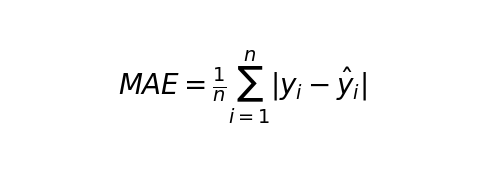

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 2))
plt.axis('off')
plt.text(0.5, 0.5, r'$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$', 
         fontsize=20, ha='center', va='center')
plt.show()

In this competition, model performance is evaluated using Mean Absolute Error (MAE), which measures the average absolute difference between actual and predicted prices. A lower MAE indicates more accurate predictions.

MAE’s main advantages are that it is easy to interpret, uses the same units as the target price, and treats all errors equally. However, this can also be a limitation, as large mistakes are not penalized as strongly as with metrics like RMSE. As a result, MAE is less sensitive to outliers, so very large errors may not have a significant impact on the score.

Overall, MAE provides a clear and intuitive way to assess model performance, directly reflecting how close the predictions are to the actual prices on average.

# 3.Categorise all variables

|Variable Kind|Number of Features|Feature Names
| --- | --- | --- |
| Numeric | 35 | host_response_rate, host_acceptance_rate, host_listings_count, latitude, longitude, accommodates, bedrooms, beds, minimum_nights, maximum_nights, minimum_minimum_nights, maximum_minimum_nights, minimum_maximum_nights, maximum_maximum_nights, minimum_nights_avg_ntm, maximum_nights_avg_ntm, availability_30, availability_60, availability_90, availability_365, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, review_scores_rating, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, calculated_host_listings_count_shared_rooms, reviews_per_month|
| ordinal  | 1 | host_response_time|
| nominal  | 11 | source, host_name, host_location, host_neighbourhood, host_verifications, neighbourhood, neighbourhood_cleansed, property_type, room_type, bathrooms, amenities |
| Boolean/Binary | 5 | host_is_superhost, host_has_profile_pic, host_identity_verified, has_availability, instant_bookable |
| Date/Time  | 3 | host_since, first_review, last_review  |
| Text  | 5 | name, description, neighborhood_overview, host_about|

# 4. Missing Values

In [8]:
import pandas as pd

# Load datasets
train_df = pd.read_csv('train.csv') 
test_df = pd.read_csv('test.csv')

# To report missing values for all variables
def full_missing_report(df, name='Data'):
    total = df.isnull().sum()
    percent = (total / len(df)) * 100
    report = pd.DataFrame({
        'Missing Count': total,
        'Missing %': percent
    })
    report = report.sort_values(by='Missing %', ascending=False)
    return report

# Generate full report
missing_train_full = full_missing_report(train_df, 'Training Data')
missing_test_full = full_missing_report(test_df, 'Test Data')

In [9]:
missing_train_full.head(30)

,Missing Count,Missing %
host_neighbourhood,3460,49.428571
host_about,2270,32.428571
neighborhood_overview,1823,26.042857
neighbourhood,1823,26.042857
host_location,1280,18.285714
bedrooms,378,5.400000
room_type,134,1.914286
neighbourhood_cleansed,108,1.542857
property_type,84,1.200000
beds,72,1.028571


In [12]:
missing_train_full.tail(30)

,Missing Count,Missing %
instant_bookable,0,0.0
calculated_host_listings_count,0,0.0
calculated_host_listings_count_entire_homes,0,0.0
calculated_host_listings_count_private_rooms,0,0.0
calculated_host_listings_count_shared_rooms,0,0.0
reviews_per_month,0,0.0
availability_90,0,0.0
maximum_nights,0,0.0
availability_30,0,0.0
has_availability,0,0.0


### 4-1. Training Dataset Findings

An assessment of the training dataset shows that several variables contain missing values. For example, host_neighbourhood is missing in nearly 49% of listings, and host_about in about 32%. Fields such as neighborhood_overview and neighbourhood also have over 26% missingness, while host_location is missing in around 18% of cases. These columns are typically optional descriptive fields that are not always provided.

Review-related variables have a relatively small proportion of missing values (about 0.3%), likely reflecting listings with no reviews. In contrast, the core variable price has no missing values, which is important for robust and reliable model training.

In [15]:
missing_test_full

,Missing Count,Missing %
host_neighbourhood,2066,68.866667
host_about,1441,48.033333
neighbourhood,1424,47.466667
neighborhood_overview,1424,47.466667
host_location,770,25.666667
host_response_rate,737,24.566667
host_response_time,737,24.566667
host_acceptance_rate,658,21.933333
review_scores_communication,300,10.000000
review_scores_checkin,300,10.000000


### 4-2. Test Dataset Findings

The test dataset indicates a similar pattern of missing values to the training data, with some fields missing at even higher rates. For example, host_neighbourhood is missing in nearly 69% of entries and host_about in about 48%. Variables such as neighbourhood and neighborhood_overview each have nearly 47% missingness, while host_location is missing in about 26% of records.

Additionally, review-related fields—including review_scores_communication—are missing in approximately 10% of test entries, a higher proportion than in the training set. This may reflect the inclusion of newer or less-reviewed listings.

Importantly, critical variables such as room_type, property_type, accommodates, and bedrooms are almost entirely complete, ensuring the model can rely on the most important predictors.


# 5. Interesting univariate data characteristics

## 5-1. Bedrooms

In [20]:
# Summary Statistics

print("Summary statistics for bedrooms:")
print(train_df['bedrooms'].describe())
print("\nValue counts for bedrooms:")
print(train_df['bedrooms'].value_counts().sort_index())

Summary statistics for bedrooms:
count    6622.000000
mean        1.785865
std         1.056360
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        14.000000
Name: bedrooms, dtype: float64

Value counts for bedrooms:
bedrooms
1.0     3351
2.0     2053
3.0      777
4.0      275
5.0      106
6.0       38
7.0       11
8.0        4
9.0        3
10.0       3
14.0       1
Name: count, dtype: int64


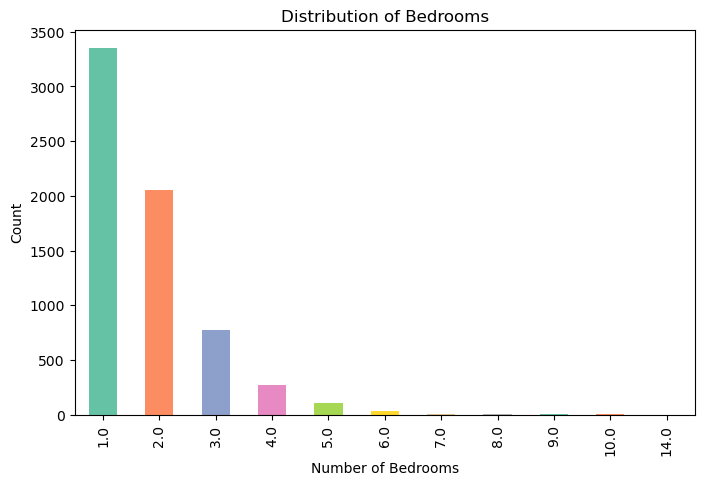

In [22]:
#Plot for Bedrooms
import seaborn as sns

counts = train_df['bedrooms'].value_counts().sort_index()
palette = sns.color_palette('Set2', n_colors=len(counts))

plt.figure(figsize=(8, 5))
counts.plot(kind='bar', color=palette)
plt.xlabel('Number of Bedrooms')
plt.ylabel('Count')
plt.title('Distribution of Bedrooms')
plt.show()

## 5-2. Accommodates

In [24]:
# Summary statistics for accommodates
print("Summary statistics for accommodates:")
print(train_df['accommodates'].describe())
print("\nValue counts for accommodates:")
print(train_df['accommodates'].value_counts().sort_index())

Summary statistics for accommodates:
count    7000.000000
mean        3.839714
std         2.514657
min         1.000000
25%         2.000000
50%         4.000000
75%         5.000000
max        16.000000
Name: accommodates, dtype: float64

Value counts for accommodates:
accommodates
1      434
2     2627
3      437
4     1656
5      372
6      711
7      133
8      304
9       46
10     114
11      30
12      55
13      11
14      19
15       3
16      48
Name: count, dtype: int64


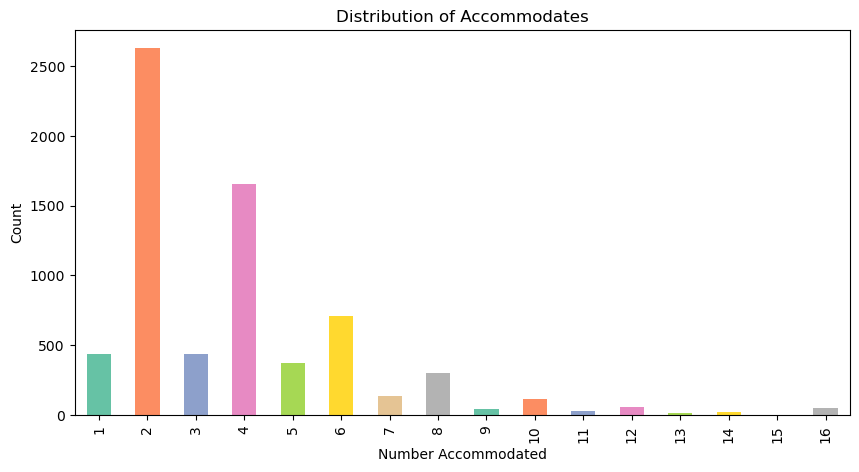

In [25]:
#Plot for Accommodates

import seaborn as sns
import matplotlib.pyplot as plt

counts_acc = train_df['accommodates'].value_counts().sort_index()
palette_acc = sns.color_palette('Set2', n_colors=len(counts_acc))

plt.figure(figsize=(10, 5))
counts_acc.plot(kind='bar', color=palette_acc)
plt.xlabel('Number Accommodated')
plt.ylabel('Count')
plt.title('Distribution of Accommodates')
plt.show()

## 5-3. Amenities

In [29]:
# Summary statistics for amenities

# Convert string to listing
import ast

def parse_amenities(x):
    try:
        return ast.literal_eval(x)
    except:
        return [a.strip() for a in x.strip('{}').replace('"','').split(',') if a.strip()]

train_df['amenities_list'] = train_df['amenities'].apply(parse_amenities)


from collections import Counter

all_amenities = [amenity for sublist in train_df['amenities_list'] for amenity in sublist]
amenity_counts = Counter(all_amenities).most_common(10)

print("Top 10 most common amenities:")
for amenity, count in amenity_counts:
    print(f"{amenity}: {count}")

Top 10 most common amenities:
Essentials: 6775
Smoke alarm: 6710
Kitchen: 6513
Hangers: 6433
Iron: 6174
Hair dryer: 6134
Wifi: 6024
Dishes and silverware: 5896
Hot water: 5826
Heating: 5605


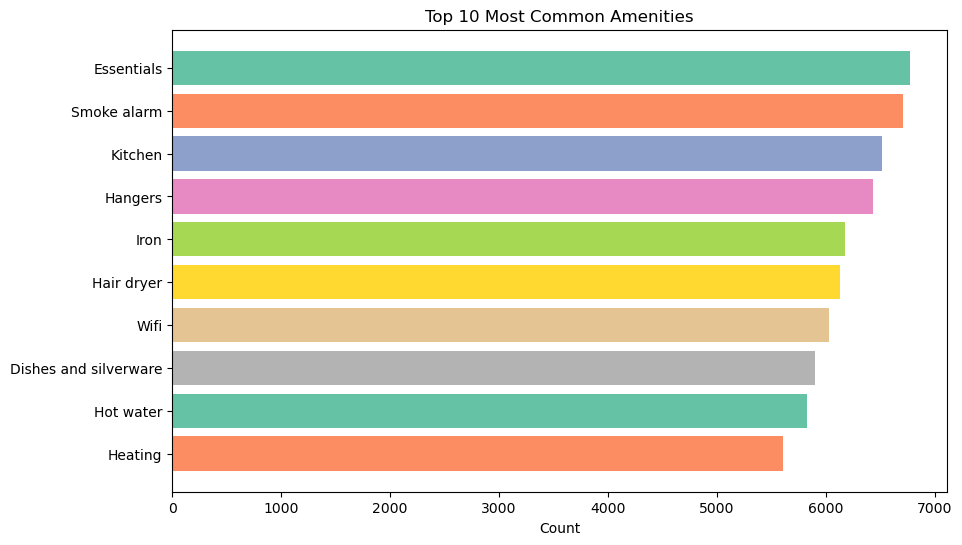

In [31]:
# Plots for Top 10 Amenities

import seaborn as sns

labels, values = zip(*amenity_counts)

palette = sns.color_palette('Set2', n_colors=len(labels)) 
plt.figure(figsize=(10, 6))
plt.barh(labels, values, color=palette)
plt.xlabel('Count')
plt.title('Top 10 Most Common Amenities')
plt.gca().invert_yaxis()
plt.show()


Most listings offer one or two bedrooms and accommodate two to four guests, aligning with demand from individuals and small groups visiting Melbourne. The prevalence of amenities such as Essentials, Kitchen, and Wifi indicates a standard for guest comfort. These features may also influence listing prices as properties offering more amenities can justify higher rates and attract more bookings.

---

## Task 2: Data Cleaning, Missing Observations and Feature Engineering

- You must clearly explain all your answers in both the Markdown file and the recorded video.

**Total Marks: 9**

Student in charge of this task: `(Kuan-Yin Lin)`

**Task 2, Question 1**: Clean **all** numerical features so that they can be used in training algorithms. For instance, `host_response_rate` feature is in object format containing both numerical values and text. Extract numerical values (or equivalently eliminate the text) so that the numerical values can be used as a regular feature.  
(2 marks)

`(Task 2, Question 1 Text Here - insert more cells as required)`

In [39]:
clean_extract = ['host_response_rate', 'host_acceptance_rate']

# Extract the numerical value
for col in clean_extract:
    if col in train_df.columns:
        train_df[col] = train_df[col].astype(str).str.replace(r'[^\d\.-]', '', regex=True)
        train_df[col] = pd.to_numeric(train_df[col], errors='coerce')  # Convert to float, set errors as NaN
for col in clean_extract:
    if col in test_df.columns:
        test_df[col] = test_df[col].astype(str).str.replace(r'[^\d\.-]', '', regex=True)
        test_df[col] = pd.to_numeric(test_df[col], errors='coerce')  # Convert to float, set errors as NaN

In [40]:
# Fill numeric columns with mean
num_cols =['host_response_rate', 'host_acceptance_rate', 'host_listings_count', 'latitude', 'longitude',
    'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights',
    'number_of_reviews_ltm','number_of_reviews_l30d' 'availability_30', 'availability_60',
    'availability_90', 'availability_365', 'number_of_reviews', 'review_scores_rating', 'review_scores_accuracy',
    'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication',
    'review_scores_location', 'review_scores_value', 'calculated_host_listings_count',
    'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms',
    'calculated_host_listings_count_shared_rooms','reviews_per_month']

for col in num_cols:
    if col in train_df.columns:
        train_df[col] = train_df[col].fillna(train_df[col].mean())
    if col in test_df.columns:
        test_df[col] = test_df[col].fillna(test_df[col].mean())

### Explaination

In this step, we clean all numerical features to ensure they are in a suitable format for training machine learning models.

Some columns, such as `host_response_rate` and `host_acceptance_rate`, were originally stored as **object types** containing a mix of numeric values and text (e.g.`"95%"`). These cannot be used directly in numerical models.

To clean them:
- We **remove non-numeric characters** (like `%` signs) using regular expressions.
- Convert the result to a numeric type using `pd.to_numeric()`, safely coercing invalid entries to `NaN`.
- Then, we **fill missing values** in all relevant numerical columns using the **mean** of each column.

This process ensures all numerical features are ready for scaling, training, and evaluation.


**Task 2, Question 2** Create at least 4 new features from existing features which contain multiple items of information.   
(2 marks)

#### 1. `host_year_rank`
We converted the `host_since` column to a datetime and extracted the **year** to evaluate how long a host has been active. Based on the year, we created a ranked categorical feature called `host_year_rank`, the longer the higher the rank.

- Rank 4: Joined ≤ 2017
- Rank 3: 2018–2019
- Rank 2: 2020–2021
- Rank 1: 2022–2023
- Rank 0: Missing values

This gives an idea of host experience which may influence pricing and reliability.

In [46]:
# Create new columns of features for host year 
# Fix datetime
train_df['host_since'] = pd.to_datetime(train_df['host_since'], errors='coerce')
test_df['host_since'] = pd.to_datetime(test_df['host_since'], errors='coerce')

# Extract year
train_df['host_since_year'] = train_df['host_since'].dt.year
test_df['host_since_year'] = test_df['host_since'].dt.year

# Map to rank 

def add_host_year_level(year):
    if pd.isna(year):
        return 0
    if year <= 2017:
        return 4
    elif year <= 2019:
        return 3
    elif year <= 2021:
        return 2
    elif year <= 2023:
        return 1

train_df['host_year_rank'] = train_df['host_since_year'].apply(add_host_year_level).astype(int)
test_df['host_year_rank'] = test_df['host_since_year'].apply(add_host_year_level).astype(int)

#### 2. Bathroom Structure Features
The `bathrooms` column contained values like `'1 shared bath'` or `'2.5 private baths'`. 
From this, we extracted:
- `bathroom_count` — the numeric count of bathrooms
- `is_shared_bath` — 1 if shared, 0 otherwise
- `is_private_bath` — 1 if private, 0 otherwise
- `is_half_bath` — 1 if half bath is mentioned

This helps model how bathroom availability and privacy influence pricing.

In [49]:
# Create new columns of new features for bathrooms, 
# which are divided into the number of rooms and boolean values to see if they are shared, private or half

import pandas as pd
import numpy as np
import re

def parse_bathroom_string(val):
    if pd.isna(val):
        return 0.0, 0, 0, 0
    val = val.lower()

    # Flag booleans
    is_shared = 1 if 'shared' in val else 0
    is_private = 1 if 'private' in val else 0
    is_half = 1 if 'half' in val else 0

    # Extract number from string
    match = re.search(r"(\d+(\.\d+)?)", val)
    if match:
        count = float(match.group(1))
    elif 'half' in val:
        count = 0.5
    else:
        count = 0.0

    return count, is_shared, is_private, is_half

def process_bathroom_column(df):
    bathroom_features = df['bathrooms'].apply(parse_bathroom_string)
    bathroom_df = pd.DataFrame(bathroom_features.tolist(), columns=[
        'bathroom_count', 'is_shared_bath', 'is_private_bath', 'is_half_bath'
    ])
    
    # Concatenate back to main DataFrame
    df = pd.concat([df, bathroom_df], axis=1)
    
    return df
train_df = process_bathroom_column(train_df)
test_df = process_bathroom_column(test_df)


####  3. Review Gap Duration
Using `first_review` and `last_review`, we calculated the number of days between the two: `review_gap_days`.  
This represents how long a listing has been active in the market with reviews — potentially reflecting popularity or listing longevity.


In [52]:
# Create new columns of features for the first review minus the last review: ['review_gap_days']
# Fix datetime
train_df['first_review'] = pd.to_datetime(train_df['first_review'], errors='coerce')
train_df['last_review'] = pd.to_datetime(train_df['last_review'], errors='coerce')
test_df['first_review'] = pd.to_datetime(test_df['first_review'], errors='coerce')
test_df['last_review'] = pd.to_datetime(test_df['last_review'], errors='coerce')

# We have to use the median to fill the missing values so that there will not be any missing values when conducting further analysis
median_first = train_df['first_review'].median()
median_last = train_df['last_review'].median()

train_df['first_review'] = train_df['first_review'].fillna(median_first)
train_df['last_review'] = train_df['last_review'].fillna(median_last)
test_df['first_review'] = test_df['first_review'].fillna(median_first)
test_df['last_review'] = test_df['last_review'].fillna(median_last)

# Use the last review day to subtract the first review day
train_df['review_gap_days'] = (train_df['last_review'] - train_df['first_review']).dt.days
test_df['review_gap_days'] = (test_df['last_review'] - test_df['first_review']).dt.days

#### 4. Price-Sensitive Amenities
We analyzed amenities from listings in the top and bottom quartiles of price distribution. From this:
- We extracted the **top amenities unique to high-price listings**
- Similarly, we extracted those unique to **low-price listings**
- Then we created binary features for each:  
  `high_amenity_<name>` and `low_amenity_<name>`, marking whether each listing includes them.
<br>  The result: Amenities for higher price: ['Dishwasher', 'Oven', 'Long term stays allowed']
<br>  The result: Amenities for lower price: ['Washer', 'Free street parking', 'TV']
<br>This allows our model to learn which amenities are associated with higher or lower pricing trends.


In [55]:
# Create the new features to identify [Amenities for higher price] and [Amenities for lower price]

# Extract "price"
from collections import Counter

train_df['price'] = train_df['price'].astype(str).str.replace(r'[^\d\.-]', '', regex=True)
train_df['price'] = pd.to_numeric(train_df['price'], errors='coerce')

# Parse amenities for both train and test
def parse_amenities(amenities_str):
    try:
        return ast.literal_eval(amenities_str)
    except:
        return [a.strip() for a in amenities_str.strip('{}').replace('"','').split(',') if a.strip()]

train_df['amenities_list'] = train_df['amenities'].apply(parse_amenities)
test_df['amenities_list'] = test_df['amenities'].apply(parse_amenities)

# --- 1. Select important amenities from TRAIN only ---

q25 = train_df['price'].quantile(0.25)
q75 = train_df['price'].quantile(0.75)

high_price = train_df[train_df['price'] >= q75]
low_price = train_df[train_df['price'] <= q25]

high_amenities = [a for sublist in high_price['amenities_list'] for a in sublist]
low_amenities = [a for sublist in low_price['amenities_list'] for a in sublist]

top20_high = [a for a, _ in Counter(high_amenities).most_common(20)]
top20_low = [a for a, _ in Counter(low_amenities).most_common(20)]

# Amenities unique to each group
unique_high = [a for a in top20_high if a not in top20_low]
unique_low = [a for a in top20_low if a not in top20_high]

# print the new features identified 
print("Amenities for higher price:", unique_high)
print("Amenities for lower price:", unique_low)

Amenities for higher price: ['Dishwasher', 'Oven', 'Air conditioning', 'Long term stays allowed']
Amenities for lower price: ['Washer', 'Free street parking', 'TV', 'Extra pillows and blankets']


In [56]:
# Add columns forr both train and test, using the above code

def add_amenity_columns(df, amenity_list, prefix):
    for amenity in amenity_list:
        safe_name = (
            amenity.replace(' ', '_')
            .replace('/', '_')
            .replace('-', '_')
            .replace('(', '')
            .replace(')', '')
            .replace('.', '_')
            .replace(':', '_')
            .replace("'", "")
            .replace('"', "")
        )
        col_name = f'{prefix}_amenity_{safe_name}'
        df[col_name] = df['amenities_list'].apply(lambda x: int(amenity in x))
    return df

# Use only amenities selected from train!
train_df = add_amenity_columns(train_df, unique_high, 'high')
test_df = add_amenity_columns(test_df, unique_high, 'high')

train_df = add_amenity_columns(train_df, unique_low, 'low')
test_df = add_amenity_columns(test_df, unique_low, 'low')

`(Task 2, Question 2 Text Here - insert more cells as required)`

**Task 2, Question 3**: Impute the missing values for all features in both the training and test datasets.   
(2 marks)

In [61]:
## Task 2, Question 3 Code Here

# Fill text columns with "Missing"
text_cols = ['name', 'description', 'neighborhood_overview','host_location','host_name', 'host_about','host_neighbourhood','neighbourhood']
for col in text_cols:
    train_df[col] = train_df[col].fillna("Missing")
    test_df[col] = test_df[col].fillna("Missing")

#### Text Columns
For free-text columns like `description`, `neighborhood_overview`, and `host_about`, we replaced missing values with the string **"Missing"** to preserve the structure while acknowledging absence.


In [64]:
# Create a mapping from property_type to its most frequent room_type
most_common_roomtype = (
    train_df.groupby('property_type')['room_type']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
)
property_to_roomtype = most_common_roomtype.to_dict()

# Fill room_type for both train and test using mapping
for df in [train_df, test_df]:
    mask = df['room_type'].isna() & df['property_type'].notna()
    df.loc[mask, 'room_type'] = df.loc[mask, 'property_type'].map(property_to_roomtype)
    
# Drop the missing values when room_type and property_type are empty (Only for train dataset)
train_df = train_df[~(train_df['room_type'].isna() & train_df['property_type'].isna())].copy()

# For test dataset, fill remaining missing room_type/property_type with 'Unknown'
test_df['room_type'] = test_df['room_type'].fillna('Unknown')
test_df['property_type'] = test_df['property_type'].fillna('Unknown')

# Fill remaining missing property_type with global mode 
property_mode = train_df['property_type'].mode()[0]
train_df['property_type'] = train_df['property_type'].fillna(property_mode)

#### `Room type` imputation based on `Property Type`
Since `room_type` and `property_type` are often correlated, we filled missing `room_type` values using the most frequent `room type` for each `property_type`. If both were missing, the rows were dropped.

We then filled remaining missing `property_type` entries using the overall mode of that column.

In [67]:
# Fill missing values with 0 
col_extract_later = ['host_response_time', 'amenities','host_verifications','bathrooms']
for col in col_extract_later:
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

#### Numerical or Structured Columns with Unparsed Text
Columns like `host_response_time`, `amenities`, `host_verifications`, and `bathrooms` were initially non-numeric. While we extract info from them in later steps, here we filled missing values with 0 as a placeholder for absence.

In [70]:
# Fill missing values in 'host_is_superhost' with its mode
mode_val = train_df['host_is_superhost'].mode()[0]

train_df['host_is_superhost'] = train_df['host_is_superhost'].fillna(mode_val)
test_df['host_is_superhost'] = test_df['host_is_superhost'].fillna(mode_val)

#### Boolean/Binary Fields
Columns `host_is_superhost` were filled using the mode, assuming the most common status is a reasonable proxy.



In [73]:
# Handle the missing values for neighbourhood_cleansed by using K-nearest Neighbors (KNN) with latitude	and longitude
from sklearn.neighbors import KNeighborsClassifier

# Train KNN on known values in train_df 
df_known = train_df[train_df['neighbourhood_cleansed'].notna()]
x_train = df_known[['latitude', 'longitude']]
y_train = df_known['neighbourhood_cleansed']

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)

# Impute missing values in train_df 
df_unknown_train = train_df[train_df['neighbourhood_cleansed'].isna()]
X_predict_train = df_unknown_train[['latitude', 'longitude']]
predicted_train = knn.predict(X_predict_train)
train_df.loc[train_df['neighbourhood_cleansed'].isna(), 'neighbourhood_cleansed'] = predicted_train

# Impute missing values in test_df 
df_unknown_test = test_df[test_df['neighbourhood_cleansed'].isna()]
X_predict_test = df_unknown_test[['latitude', 'longitude']]
predicted_test = knn.predict(X_predict_test)
test_df.loc[test_df['neighbourhood_cleansed'].isna(), 'neighbourhood_cleansed'] = predicted_test


#### Imputation Using KNN: `neighbourhood_cleansed`
This categorical location-based feature was imputed using a K-Nearest Neighbors (KNN) classifier, trained on known latitude and longitude coordinates. This approach helps estimate the most likely neighborhood based on geographical proximity — a smarter alternative to using global mode.

`(Task 2, Question 3 Text Here - insert more cells as required)`

**Task 2, Question 4**: Encode all categorical variables appropriately as discussed in class.

- Where multiple values are given for an observation encode the observation as 'other'.
- Where a categorical feature contains more than 5 unique values, map the features into 5 most frequent values + 'other' and then encode appropriately.  
(2 marks)

#### `room_type`  
Top 5 room types were retained. All other rare room types were grouped as `'other'`, and one-hot encoded


In [79]:
## Task 2, Question 4 Code Here
# Get top 5 room types from train set
top_5_room_types = train_df['room_type'].value_counts().nlargest(5).index

# Replace less frequent categories with 'other'
train_df['room_type_other'] = train_df['room_type'].apply(lambda x: x if x in top_5_room_types else 'other')
test_df['room_type_other'] = test_df['room_type'].apply(lambda x: x if x in top_5_room_types else 'other')

# One-hot encode and convert to int
train_room_dummies = pd.get_dummies(train_df['room_type_other'], prefix='room_type')
test_room_dummies = pd.get_dummies(test_df['room_type_other'], prefix='room_type')

# Convert all to int to prevent dtype mismatch
train_room_dummies = train_room_dummies.astype(int)
test_room_dummies = test_room_dummies.astype(int)

# Align dummy columns between train and test
train_room_dummies, test_room_dummies = train_room_dummies.align(test_room_dummies, join='outer', axis=1, fill_value=0)

# Concatenate dummies to the original DataFrames
train_df = pd.concat([train_df, train_room_dummies], axis=1)
test_df = pd.concat([test_df, test_room_dummies], axis=1)

#later we will drop the original column

#### `neighbourhood_cleansed`  
We kept only the 5 most common neighborhoods in the training set and grouped others as 'Other'

In [82]:
#One-hot encoding for neighbourhood_cleansed
top5_train = train_df['neighbourhood_cleansed'].value_counts().head(5).index.tolist()

train_df['top5_neighbourhood'] = train_df['neighbourhood_cleansed'].apply(lambda x: x if x in top5_train else 'Other')
test_df['top5_neighbourhood'] = test_df['neighbourhood_cleansed'].apply(lambda x: x if x in top5_train else 'Other')

train_neigh_dummies = pd.get_dummies(train_df['top5_neighbourhood'], prefix='neighbourhood').astype(int)
test_neigh_dummies = pd.get_dummies(test_df['top5_neighbourhood'], prefix='neighbourhood').astype(int)

train_df = pd.concat([train_df, train_neigh_dummies], axis=1)
test_df = pd.concat([test_df, test_neigh_dummies], axis=1)
# Later we will drop the original column

#### `host_location`
We simplified this geographic field by retaining the 5 most common locations and encoding accordingly.

In [85]:
one_hot_code_cols = ['host_location']

for col in one_hot_code_cols:
    
    # Find top 5 frequent values from train
    top_5 = train_df[col].value_counts().nlargest(5).index

    # Replace rare values with 'other'
    train_df[col] = train_df[col].apply(lambda x: x if x in top_5 else 'other')
    test_df[col] = test_df[col].apply(lambda x: x if x in top_5 else 'other')

    # One-hot encode with pd.get_dummies()
    train_dummies = pd.get_dummies(train_df[col], prefix=col).astype(int)
    test_dummies = pd.get_dummies(test_df[col], prefix=col).astype(int)

    # Align both train and test (so columns match)
    train_dummies, test_dummies = train_dummies.align(test_dummies, join='outer', axis=1, fill_value=0)

    # Concatenate the new dummies to the main dataframes
    train_df = pd.concat([train_df, train_dummies], axis=1)
    test_df = pd.concat([test_df, test_dummies], axis=1)

#later we will drop the original column

#### `host_response_time`
This ordinal variable was mapped to rank-based integers for model interpretability:

- within an hour → 4
- within a few hours → 3
- within a day → 2
- a few days or more → 1
- unknown → 0


In [88]:
#Convert the values of host_response_time into categorical values

def add_host_response_level(text):
    if text == 'within an hour':
        return 4
    elif text == 'within a few hours':
        return 3
    elif text == 'within a day':
        return 2
    elif text == 'a few days or more':
        return 1
    else: return 0

train_df['host_response_rank'] = train_df['host_response_time'].apply(add_host_response_level)
test_df['host_response_rank'] = test_df['host_response_time'].apply(add_host_response_level)

#later we will drop the original column

#### `host_verifications`
This field contained multiple verification methods as stringified lists. We created a numeric score based on the number of verification types:

- 3 or more verifications → 3
- 2 verifications → 2
- 1 verification → 1
- 0 or error → 0



In [91]:
import ast

def count_verifications(val):
    try:
        # Safely convert string to list
        items = ast.literal_eval(val)

        # If it's a list, return its length (max capped at 3)
        if isinstance(items, list):
            count = len(items)
            if count >= 3:
                return 3
            elif count == 2:
                return 2
            elif count == 1:
                return 1
            else:
                return 0
        else:
            return 0
    except:
        return 0  # Return 0 if parsing fails

train_df['host_verifications_score'] = train_df['host_verifications'].apply(count_verifications)
test_df['host_verifications_score'] = test_df['host_verifications'].apply(count_verifications)

# Later we will drop the original column

#### Boolean Encoding
Converting categorical boolean-like values into integers allows algorithms to interpret and process these features numerically, improving model accuracy and avoiding data type errors during training.

We defined a function `map_bool_column()` to map:
- `'t'` or `True` → 1
- `'f'` or `False` → 0

This function was applied to both training and test datasets on the following columns:

- `has_availability`
- `host_has_profile_pic`
- `host_is_superhost`
- `host_identity_verified`
- `instant_bookable`

Each column was converted to `int` type after mapping to ensure proper numerical format for modeling.



In [94]:
# Define a function to map boolean-like string values to binary integers
# 't' and True become 1, 'f' and False become 0
def map_bool_column(col):
    return col.map({'t': 1, 'f': 0, True: 1, False: 0}).astype(int)

# List of columns with boolean or 't'/'f' string values to be encoded
bool_cols = ['has_availability', 'host_has_profile_pic', 'host_is_superhost', 
             'host_identity_verified', 'instant_bookable']

# Apply the binary mapping to both train and test datasets for each column
for col in bool_cols:
    train_df[col] = map_bool_column(train_df[col])
    test_df[col] = map_bool_column(test_df[col])

`(Task 2, Question 4 Text Here - insert more cells as required)`

**Task 2, Question 5**: Perform any additional data preparation steps you consider necessary before building your predictive models, and clearly explain each action you take.  
(1 mark)

In [98]:
## Task 2, Question 5 Code Here

In [100]:
# Check the extreme outliers
sorted_df = train_df.sort_values(by='price', ascending=False)
print(sorted_df[['bedrooms', 'bathrooms', 'accommodates', 'room_type', 'price', 'neighbourhood_cleansed']].head(10))

      bedrooms      bathrooms  accommodates        room_type     price  \
4170  1.785865         1 bath             2  Entire home/apt  145160.0   
3895  1.000000  1 shared bath             2     Private room  104983.0   
665   1.785865         1 bath             3  Entire home/apt   55419.0   
6838  1.785865         1 bath             4  Entire home/apt   40844.0   
2356  2.000000        2 baths             4  Entire home/apt   17988.0   
2224  1.000000         1 bath             2  Entire home/apt   16429.0   
3619  1.785865         1 bath             5  Entire home/apt    9999.0   
4722  3.000000         1 bath             6  Entire home/apt    9999.0   
4246  2.000000         1 bath             5  Entire home/apt    8499.0   
4484  1.000000  1 shared bath             2     Private room    5750.0   

     neighbourhood_cleansed  
4170              Melbourne  
3895             Boroondara  
665                   Yarra  
6838              Melbourne  
2356           Port Phillip  
2224 

###  Final Outlier Removal Based on Price Threshold

After previously applying the IQR method to handle outliers in `price`, we noticed that a few **extremely high-priced listings** still remained — often with values exceeding \$100,000 AUD. While not technically outliers under IQR, these listings are rare and can **heavily skew the model**.

---

### What We Did:
- Sorted the training dataset by `price` in descending order.
- Reviewed the top 10 most expensive listings using key variables:  
  `bedrooms`, `bathrooms`, `accommodates`, `room_type`, and `neighbourhood_cleansed`.
- Identified that listings with prices **above \$20,000** likely represent special-use or incorrectly recorded properties.


In [103]:
# Drop only the price over 20,000
train_df = train_df[train_df['price'] < 20000].copy()

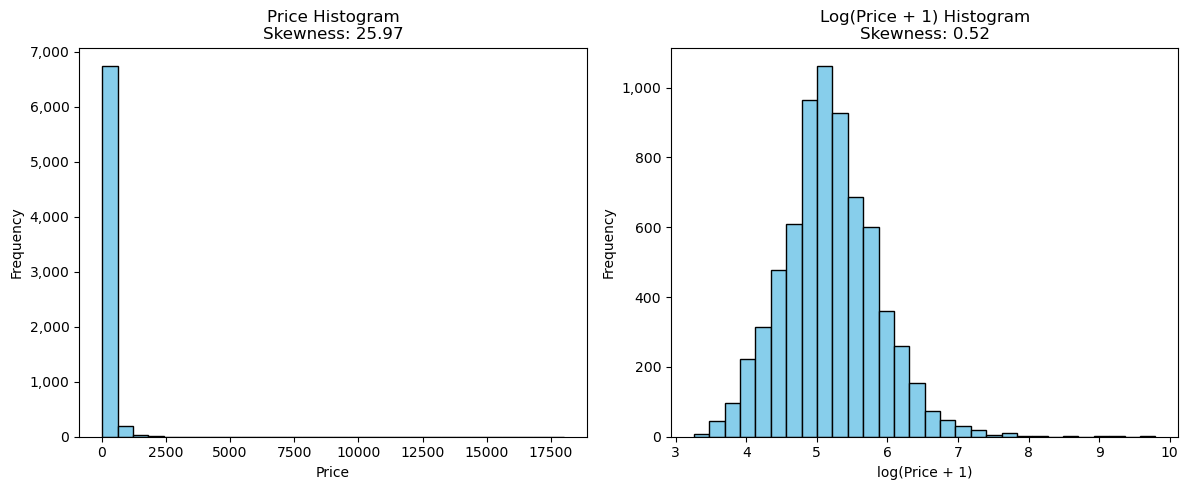

In [105]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.stats import skew

# Calculate skewness of the original 'price' column
price_skew = skew(train_df['price'].dropna())

# Apply log1p transformation to handle skewness and outliers
log_price = np.log1p(train_df['price'])

# Calculate skewness after log transformation
log_price_skew = skew(log_price.dropna())

# Store the log-transformed price in the dataframe for later use
train_df['log_price'] = log_price

# Create a figure with 1 row and 2 columns for side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---------- Left Plot: Histogram of Raw Price ----------
axes[0].hist(train_df['price'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title(f'Price Histogram\nSkewness: {price_skew:.2f}')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Frequency')
# Format y-axis ticks with thousand separators
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# ---------- Right Plot: Histogram of Log-Transformed Price ----------
axes[1].hist(train_df['log_price'], bins=30, color='skyblue', edgecolor='black')
axes[1].set_title(f'Log(Price + 1) Histogram\nSkewness: {log_price_skew:.2f}')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Frequency')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Adjust layout to prevent overlapping labels and titles
plt.tight_layout()

# Display the plot
plt.show()



###  Addressing Skewness in `price` Using Log Transformation

Airbnb listing prices are often **right-skewed** due to a small number of extremely high-priced listings. This kind of skew can degrade the performance of many regression models, especially linear ones.

---

### What We Did:

1. **Removed listings with prices ≥ \$20,000**  
   These were determined to be unrealistic or exceptional and could distort the training process.

2. **Calculated Skewness** of the original `price` column using SciPy's `skew()` function.

3. **Applied a log transformation** using `np.log1p(price)`, which is equivalent to:
   \[
   \log(1 + \text{price})
   \]
   This transformation:
   - Compresses large values
   - Spreads small values
   - Retains zero entries safely

4. **Compared Skewness Before vs After**:
   - **Before:** `Skewness ≈ {price_skew:.2f}`
   - **After:** `Skewness ≈ {log_price_skew:.2f}`

5. **Visualized both distributions** side by side using histograms to clearly show the normalization effect of the log transform.

---

### Why This Matters:

| Issue                  | Solution                    |
|------------------------|-----------------------------|
| Right-skewed `price`   | Use `log1p(price)`          |
| Outliers dominate      | Log transform compresses them |
| Linear model underperforms | Skewness reduction improves fit |
| Metrics like MAE unstable | More stable and consistent error |



In [108]:
# drop columns from df
drop_cols = [
    'ID', 'source', 'name', 'description', 'bathrooms', 'neighborhood_overview', 'host_name',
    'property_type', 'host_about', 'host_neighbourhood', 'neighbourhood', 'first_review',
    'last_review', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'minimum_minimum_nights',
    'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights','price'
]

train_df = train_df.drop(columns=drop_cols, errors='ignore')
test_df = test_df.drop(columns=drop_cols, errors='ignore')

In [110]:
# Drop original column when creating new features

train_df = train_df.drop(columns=['host_since', 'host_since_year','amenities', 'amenities_list'])

test_df = test_df.drop(columns=['host_since', 'host_since_year','amenities', 'amenities_list'])

# Delete the KNN 'neighbourhood_cleansed'column
train_df.drop(columns=['neighbourhood_cleansed'], inplace=True)
test_df.drop(columns=['neighbourhood_cleansed'], inplace=True)

train_df.drop(columns=['top5_neighbourhood'], inplace=True)
test_df.drop(columns=['top5_neighbourhood'], inplace=True)

train_df.drop(columns=['host_location_Missing'], inplace=True)
test_df.drop(columns=['host_location_Missing'], inplace=True)


In [111]:
# Encoding original column drop

# Drop all specified columns from train and test datasets
cols_to_drop = [
    'room_type', 'room_type_other',
    'host_location', 'host_response_time',
    'host_verifications'
]

train_df.drop(columns=cols_to_drop, inplace=True)
test_df.drop(columns=cols_to_drop, inplace=True)

###  Columns Dropped and reasons:

#### 1. **Duplicate or Irrelevant Columns:**
- `ID`, `source`: Identifiers with no predictive value.
- `host_name`, `host_about`, `description`, `name`: Free-text fields with high cardinality or missing values that add little predictive signal.
- `property_type`, `neighbourhood`, `host_neighbourhood`, `neighborhood_overview`: Already handled via encoding or aggregated features.
- `minimum_nights_avg_ntm`, `maximum_nights_avg_ntm`, `minimum_minimum_nights`, `maximum_minimum_nights`,`minimum_maximum_nights`, `maximum_maximum_nights`: These columns are redundant, highly correlated with existing features, and add little predictive value. They are removed to simplify the model.

#### 2. **Original Features Already Processed:**
- `host_since`, `host_since_year`: Transformed into `host_year_rank`.
- `bathrooms`: Parsed into meaningful sub-features (`bathroom_count`, `is_shared_bath`, etc.).
- `amenities`, `amenities_list`: Transformed into binary indicators for high-price and low-price amenities.

#### 3. **Encoded Columns (Removed after Encoding):**
- `room_type`, `room_type_other`: One-hot encoded versions used instead.
- `host_location`, `host_response_time`, `host_verifications`: Converted to encoded features like ranks or verification counts.

#### 4. **Location Imputation Columns:**
- `neighbourhood_cleansed`: Imputed using KNN and simplified to a top-5 category.
- `top5_neighbourhood`: Used only for intermediate encoding.
- `host_location_Missing`: Not useful after imputation.


`(Task 2, Question 5 Text Here - insert more cells as required)`

---
## Task 3: Fit and tune predictive models, submit predictions & win competition

- You must clearly explain all your answers in both the Markdown file and the recorded video.
-
**Total Marks: 9**

For this task, you should not create any new features and must rely on the variables constructed in Task 2.  


1. Perform some EDA to measure the relationship between the features and the target variable, and carefully explain your findings. (2 marks)

2. Choose and carefully explain 3 different machine learning (ML) regression models that you will apply in this competition. (2 marks)
   
3. Train the models from the above question and tune their hyperparameters via cross-validation. Discuss the fitted weights, optimised hyperparameter values, and their training dataset predictive performance. (2 marks)   

4. Select your best model, create predictions of the test dataset and submit your forecasts on Kaggle's competition page. Provide Kaggle ranking and score (screenshots) and comment on your performance in the competition. (2 marks)

5. Suggest ways to improve your ranking and implement them, providing further evidence from Kaggle (screenshots). (1 mark)   

- Hints:
    - Make sure your Python code works so that your results can be replicated by the marker
    - You will receive the mark of zero for this Task if your code does not produce the forecasts uploaded to Kaggle



#### **1. Perform some EDA to measure the relationship**

Student in charge of this task: `Hung-Chih(April), Su`

In [119]:
#Task 3 code here
train_df.shape

(6994, 66)

In [121]:
# Correlation with the target
encoded_numeric_df = pd.get_dummies(train_df, drop_first=True)

corr_with_target = encoded_numeric_df.corr()['log_price'].sort_values(ascending=False)
display(corr_with_target)

log_price                    1.000000
accommodates                 0.584818
bedrooms                     0.564701
beds                         0.509187
room_type_Entire home/apt    0.500578
                               ...   
is_private_bath             -0.156377
neighbourhood_Other         -0.226911
is_shared_bath              -0.470545
room_type_Private room      -0.512486
has_availability                  NaN
Name: log_price, Length: 66, dtype: float64

#### **Interpretation:**
Identify features with the highest positive/negative correlation with the target (Log-price). For house price, features like `bedrooms`, `accommodates`, and `number_of_reviews` might show moderate to strong relationships.

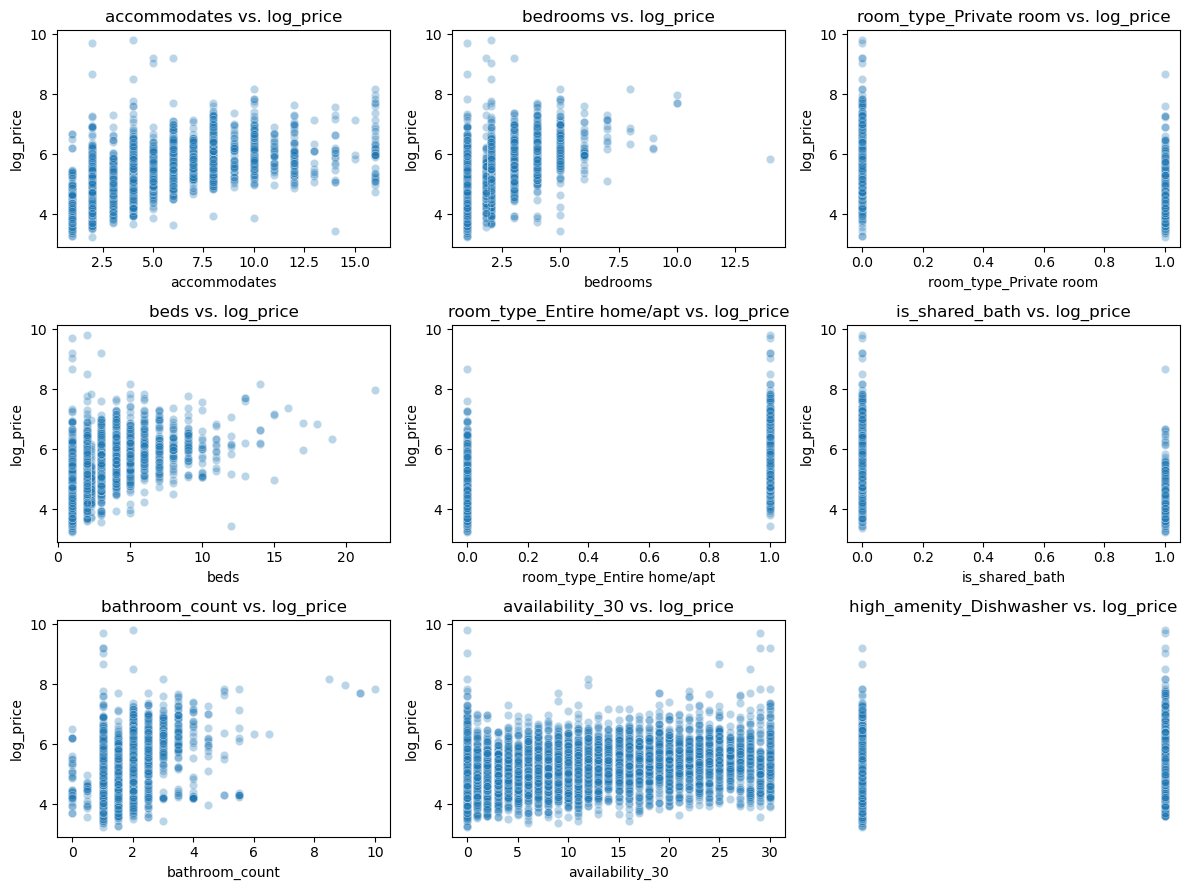

In [160]:
# Visualize top correlated features with log_price using scatterplots

# Select top features
top_n = 9
top_features = corr_with_target.drop('log_price').abs().sort_values(ascending=False).head(top_n).index

# Plot the correlation between log_price and features
n_cols = 3
n_rows = int(np.ceil(len(top_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows*3))

for i, feature in enumerate(top_features):
    row, col = divmod(i, n_cols)
    ax = axes[row, col]
    sns.scatterplot(
        x=encoded_numeric_df[feature],
        y=encoded_numeric_df['log_price'],
        alpha=0.3,
        ax=ax
    )
    ax.set_title(f'{feature} vs. log_price')

# If odd number, hide the last empty subplot
if len(top_features) % 2 != 0:
    axes[-1, -1].axis('off')

plt.tight_layout()
plt.show()

#### **Interpretation:**
The scatterplots show that features such as accommodates, bedrooms, and beds all have clear positive relationships with log-transformed price; listings with more rooms or space tend to be more expensive. For categorical variables represented by dummy variables (like room type and neighbourhood), there are visible differences in price: entire homes and properties in certain neighbourhoods generally have higher prices, while private rooms are priced lower. Some features, like availability and high amenities (e.g., having a dishwasher), show less obvious or weaker patterns with price. Overall, the most important predictors for price appear to be the physical attributes of the listing and its type or location.

#### **2. Choose and explain 3 different machine learning (ML) regression models**

In [129]:
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import uniform, randint
from xgboost import XGBRegressor
import shap
import matplotlib.pyplot as plt

In [130]:
# Data Preparation

target = 'log_price'
X_train = train_df.drop(columns=[target])
y_train = train_df[target]
X_test = test_df[X_train.columns]

In [131]:
# Model 1: Linear Regression
linreg_model = LinearRegression()

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Fit the model
linreg_model.fit(X_train_scaled, y_train)

# Then predict
y_train_pred = linreg_model.predict(X_train_scaled)

# Now print the metrics
print("Linear Regression:")
print("MAE (log scale):", mean_absolute_error(y_train, y_train_pred))
print("R² (log scale):", r2_score(y_train, y_train_pred))
print("MAE (original price):", mean_absolute_error(np.expm1(y_train), np.expm1(y_train_pred)))



Linear Regression:
MAE (log scale): 0.2926766509702116
R² (log scale): 0.6410601373932978
MAE (original price): 83.2115692537155


In [132]:
# Model 2: Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42)

# Fit the model
rf_model.fit(X_train, y_train)

# Then predict
y_train_pred = rf_model.predict(X_train)

# Print the metrics
print("Random Forest Regressor:")
print("MAE (log scale):", mean_absolute_error(y_train, y_train_pred))
print("R² (log scale):", r2_score(y_train, y_train_pred))
print("MAE (original price):", mean_absolute_error(np.expm1(y_train), np.expm1(y_train_pred)))

Random Forest Regressor:
MAE (log scale): 0.09269258199486513
R² (log scale): 0.9593235837912504
MAE (original price): 33.1278322033378


In [133]:
# Model 3: XGBoost Regressor
xgb_model = XGBRegressor(objective='reg:squarederror', tree_method='hist', random_state=42)

# Fit the model
xgb_model.fit(X_train, y_train)

# Predict on the training data
y_train_pred = xgb_model.predict(X_train)

# Evaluate metrics
print("XGBoost Regressor:")
print("MAE (log scale):", mean_absolute_error(y_train, y_train_pred))
print("R² (log scale):", r2_score(y_train, y_train_pred))

# Convert back to original price scale (since you used log1p for training)
mae_original = mean_absolute_error(np.expm1(y_train), np.expm1(y_train_pred))
print("MAE (original price):", mae_original)

XGBoost Regressor:
MAE (log scale): 0.08558037036698143
R² (log scale): 0.9703661996510651
MAE (original price): 23.45133889318024


|Model Used|Reasons
| --- | --- |
| Linear Regression | This is a simple and interpretable model. After log-transforming price, it works well for finding basic relationships between features and price. It is good as a starting baseline. |
|  Random Forest Regressor  | This tree-based model can find complex patterns and handle both numbers and categories well. It is strong at handling outliers and does not assume data is normal, which is helpful for housing data.|
| XGBoost Regressor  | XGBoost is a popular and powerful model that usually gives very good results on structured data like this. It can find non-linear patterns, handle many features, and is often used in data science competitions. |

#### **3. Train the models from the above question and tune their hyperparameters via cross-validation**

In [136]:
# Model 1: Linear Regression

# Train and evaluate Linear Regression
linreg_model.fit(X_train_scaled, y_train)
y_train_pred = linreg_model.predict(X_train_scaled)
print("Linear Regression:")
print("MAE (log scale):", mean_absolute_error(y_train, y_train_pred))
print("R² (log scale):", r2_score(y_train, y_train_pred))

# Original price scale
y_train_original = np.expm1(y_train)
y_train_pred_original = np.expm1(y_train_pred)
mae_original = mean_absolute_error(y_train_original, y_train_pred_original)

print(f"MAE (original price): {mae_original:.2f}")

# Cross-validation
cv_scores = -cross_val_score(linreg_model, X_train, y_train, scoring='neg_mean_absolute_error', cv=5)
print(f"Cross-validated MAE (log scale): {cv_scores.mean():.2f} ± {cv_scores.std():.2f}")

Linear Regression:
MAE (log scale): 0.2926766509702116
R² (log scale): 0.6410601373932978
MAE (original price): 83.21
Cross-validated MAE (log scale): 0.30 ± 0.01


#### **Interpretation:**
Since Linear Regression is a baseline model and has no major hyperparameters to tune, it was trained using all available features. The model estimated a coefficient for each feature, indicating its effect on the log-transformed price. The results showed an R² of 0.64, a training MAE (original price) of 82.86, and a cross-validated MAE (log scale) of 0.30.

In [138]:
# Model 2: Random Forest Regressor
param_dist_rf = {
    'n_estimators': randint(100, 600),
    'max_depth': randint(2, 12),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 6),
    'max_features': ['sqrt', 'log2']
}

random_search_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist_rf,
    n_iter=50,
    scoring='neg_mean_absolute_error',
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42
)
random_search_rf.fit(X_train, y_train)
best_rf = random_search_rf.best_estimator_
print("Random Forest Regressor:")
print("Best RF Hyperparameters:", random_search_rf.best_params_)

# Evaluate on training set
y_train_pred = best_rf.predict(X_train)
print("MAE (log scale):", mean_absolute_error(y_train, y_train_pred))
print("R² (log scale):", r2_score(y_train, y_train_pred))

y_train_pred_original = np.expm1(y_train_pred)
mae_original = mean_absolute_error(y_train_original, y_train_pred_original)
print(f"MAE (original price): {mae_original:.2f}")

# Cross-validation
cv_scores = -cross_val_score(best_rf, X_train, y_train, scoring='neg_mean_absolute_error', cv=5)
print(f"Cross-validated MAE: {cv_scores.mean():.2f} ± {cv_scores.std():.2f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Random Forest Regressor:
Best RF Hyperparameters: {'max_depth': 11, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 306}
MAE (log scale): 0.20211619541750137
R² (log scale): 0.8208456512153801
MAE (original price): 61.56
Cross-validated MAE: 0.27 ± 0.01


#### **Interpretation:**
We trained the Random Forest Regressor using cross-validation and hyperparameter tuning. The best hyperparameters were: max_depth=11, n_estimators=306, min_samples_leaf=3, and max_features='sqrt'. The model achieved an R² of 0.82, a training MAE (original price) of 61.56, and a cross-validated MAE of 0.27.

In [140]:
# Model 3: XGBoost regressor 

param_dist_xgb = {
    'n_estimators': randint(100, 600),
    'max_depth': randint(2, 5),
    'learning_rate': uniform(0.01, 0.05),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'gamma': uniform(0, 5)
}

random_search_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist_xgb,
    n_iter=50,
    scoring='neg_mean_absolute_error',
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42
)
random_search_xgb.fit(X_train, y_train)
best_xgb = random_search_xgb.best_estimator_
print(" XGBoost regressor:")
print("Best XGB Hyperparameters:", random_search_xgb.best_params_)

# Evaluate on training set
y_train_pred = best_xgb.predict(X_train)
print("MAE (log scale):", mean_absolute_error(y_train, y_train_pred))
print("R² (log scale):", r2_score(y_train, y_train_pred))

y_train_pred_original = np.expm1(y_train_pred)
mae_original = mean_absolute_error(y_train_original, y_train_pred_original)
print(f"MAE (original price): {mae_original:.2f}")

# Cross-validation
cv_scores = -cross_val_score(best_xgb, X_train, y_train, scoring='neg_mean_absolute_error', cv=5)
print(f"Cross-validated MAE: {cv_scores.mean():.2f} ± {cv_scores.std():.2f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
 XGBoost regressor:
Best XGB Hyperparameters: {'colsample_bytree': 0.6746074041599417, 'gamma': 0.20387570777381958, 'learning_rate': 0.03954464715941209, 'max_depth': 4, 'n_estimators': 519, 'subsample': 0.6066351315711425}
MAE (log scale): 0.18534012445470505
R² (log scale): 0.8578120997788807
MAE (original price): 54.41
Cross-validated MAE: 0.25 ± 0.01


#### **Interpretation:**
We tuned XGBoost using RandomizedSearchCV. The optimal hyperparameters included max_depth=4, n_estimators=519, learning_rate=0.04, colsample_bytree=0.67, and subsample=0.61, with a R² of 0.86, a training MAE (original price) of 54.41, and a cross-validated MAE of 0.25.

Although the untuned Random Forest and XGBoost models showed lower MAE and higher R² on the training set, these scores likely result from overfitting. After tuning hyperparameters using cross-validation, the MAE on the training set increased, but the cross-validated MAE better reflects the model’s generalization ability. Cross-validation penalizes overfitting and provides a more realistic estimate of performance on new data. Therefore, the tuned models are more reliable, even if their training metrics are less impressive.

#### **Reasons why we choose XGBoost Regressor as our prediction model:**
In this competition, we chose XGBoost Regressor as our prediction model because it gave the best results out of all three models. It had the lowest MAE and the highest R², which means it predicted house prices more accurately and explained more of the data’s variation. Compared to linear regression and random forest, XGBoost was better at capturing complex patterns in the data. After hyperparameter tuning and cross-validation, it consistently delivered the strongest performance that making it the top choice for this competition.

In [144]:
# Fit final XGBoost model using all training data
params = random_search_xgb.best_params_
best_xgb_model = XGBRegressor(**params, random_state=42)
best_xgb_model.fit(X_train, y_train)

# Make predictions on the test set (still in log_price units)
best_xgb_predictions_log = best_xgb_model.predict(X_test)

# Convert log predictions back to original price
best_xgb_predictions = np.expm1(best_xgb_predictions_log)

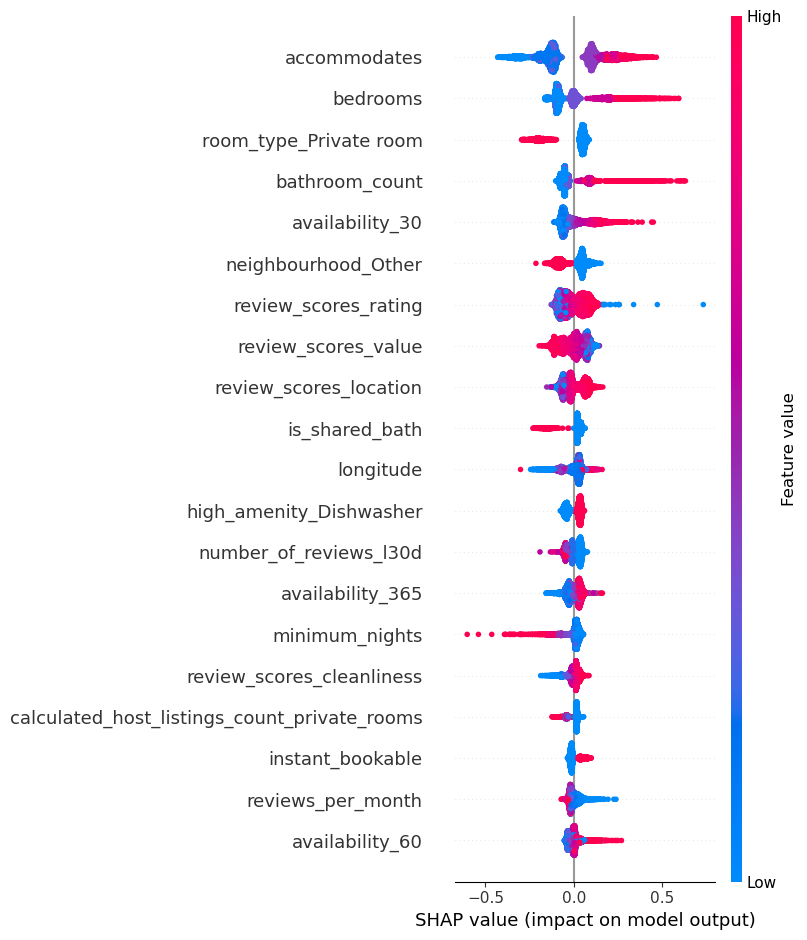

In [148]:
# Shows which features contribute most to the model based on information gain

# Use SHAP to interpret the XGBoost model (global and local feature importance)
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_train)

shap.summary_plot(shap_values, X_train)

#### **Interpretation:**
The SHAP plot can help us identify the most important features in the XGBoost model for predicting price. We use SHAP to check not only which features are strong predictors (like accommodates, bedrooms, and room type), but also to spot any surprising or potentially problematic features that might be influencing the model, such as neighbourhood_Other. In the plot, higher values of these top features generally push the predicted price up, which makes sense. Each dot shows how much a feature affected the price for one listing, with color indicating whether the value is high (red) or low (blue).

In [150]:
# create predictions of the test dataset 
original_test = pd.read_csv('test.csv')

# Extract just the 'id' column
test_ids = original_test['ID']

submission = pd.DataFrame({
   'ID': test_ids,                 
   'price': best_xgb_predictions    
})

submission.to_csv('submission_XGB_Shecodes.csv', index=False)
print("Submission with restored 'id' created!")

Submission with restored 'id' created!


#### **4. Select your best model and create predictions on Kaggle's competition page**

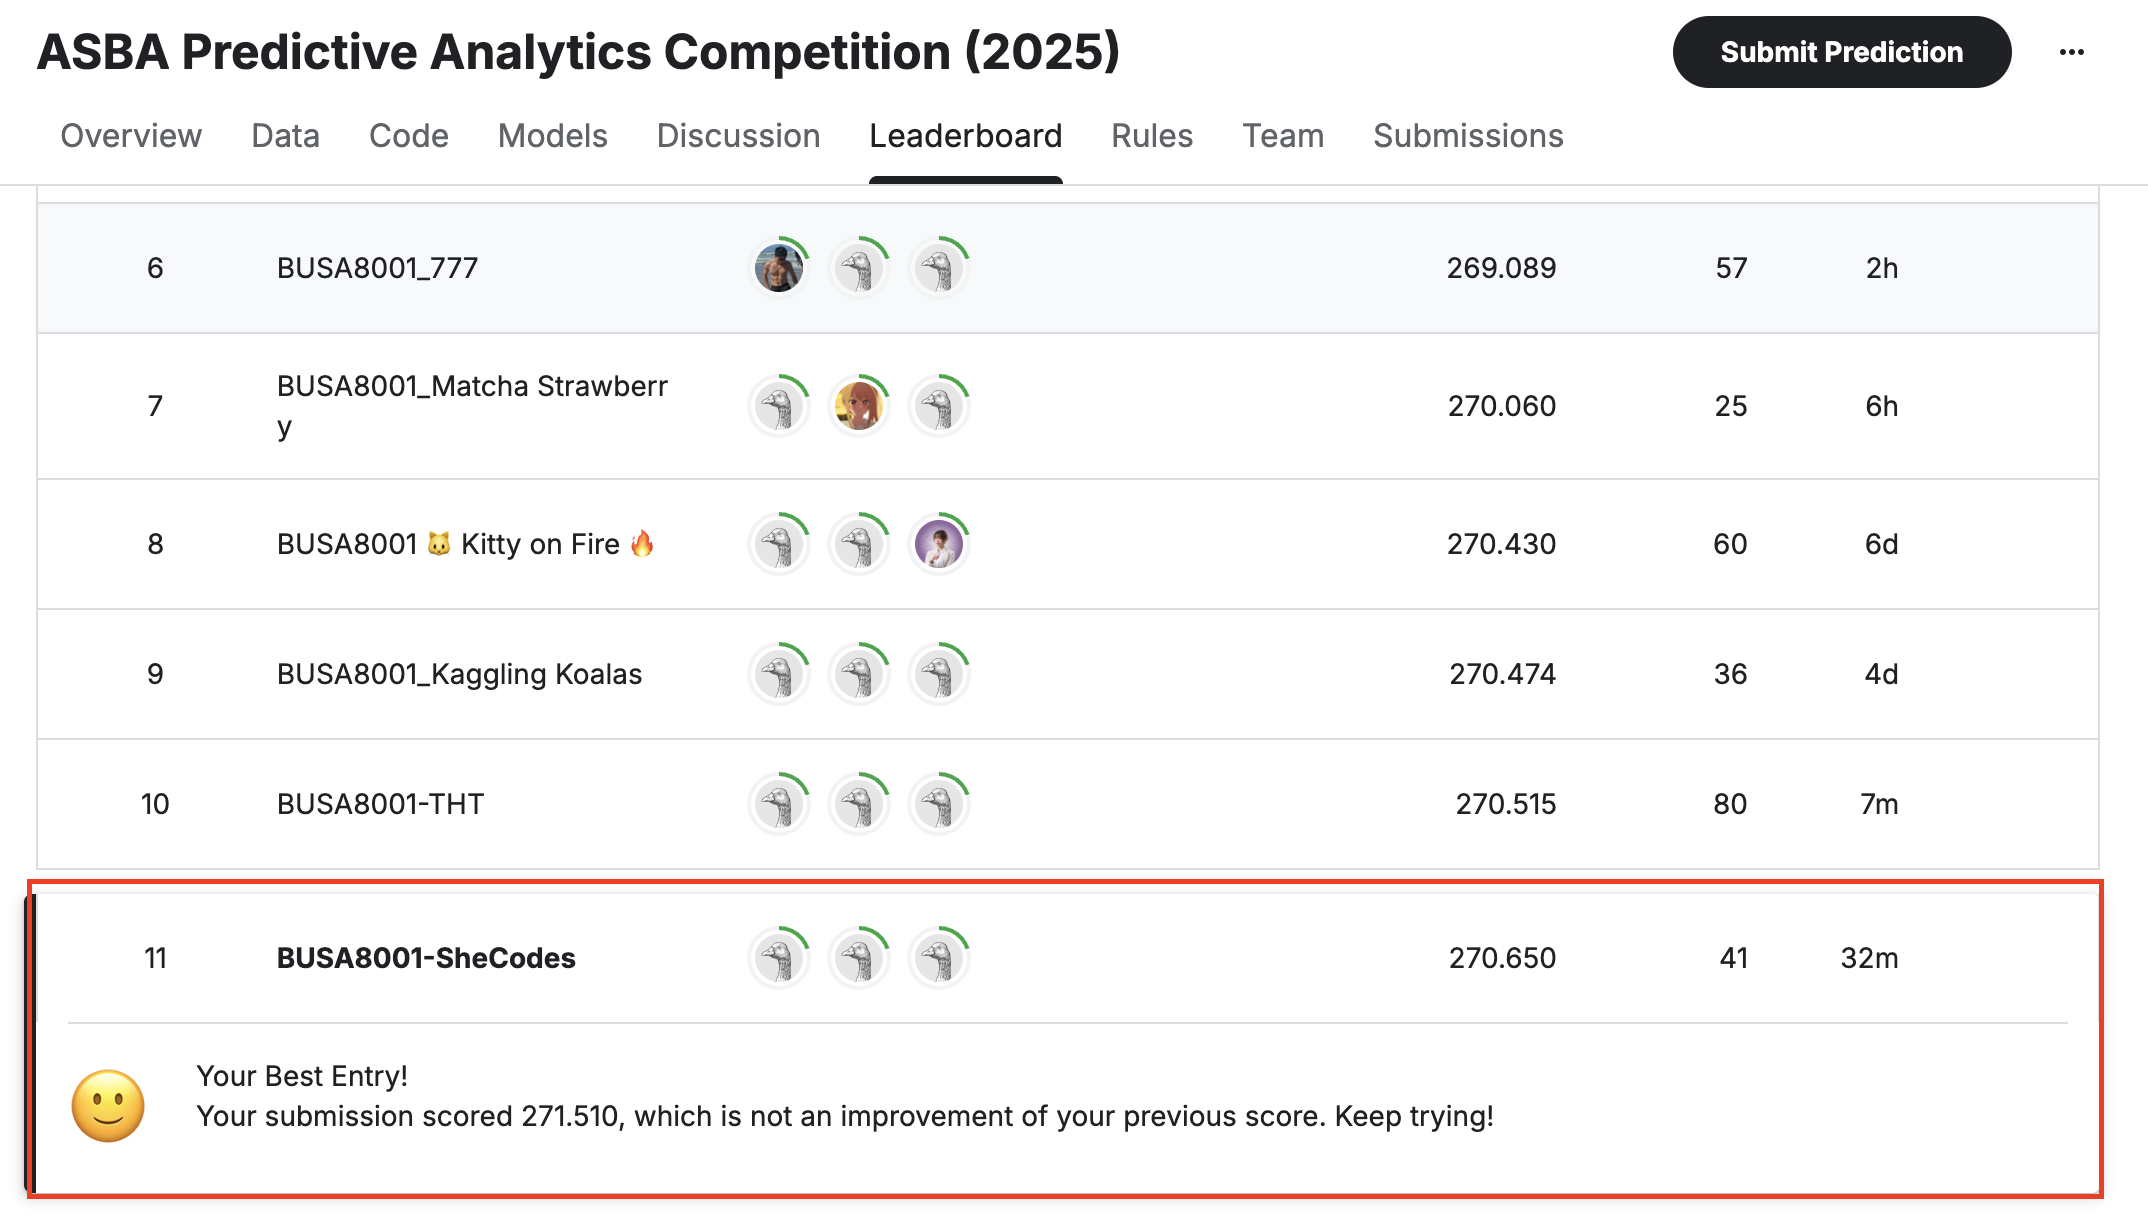

For our final submission, we selected the XGBoost Regressor as our best-performing model. This model was chosen based on cross-validated MAE and its performance in handling non-linear relationships and feature interactions in the dataset. While our model achieved a great position (Rank 11) on the leaderboard, there is still a gap between our score and the top-performing teams. The XGBoost model provided stable and relatively accurate predictions, but there may be further room for improvement through advanced feature engineering in part two and additional data cleaning. Competing in this challenge has deepened our understanding of model evaluation and the importance of cross-validation, and it has motivated us to explore further methods for enhancing predictive accuracy.

#### **5. Suggest ways to improve your ranking and implement them**

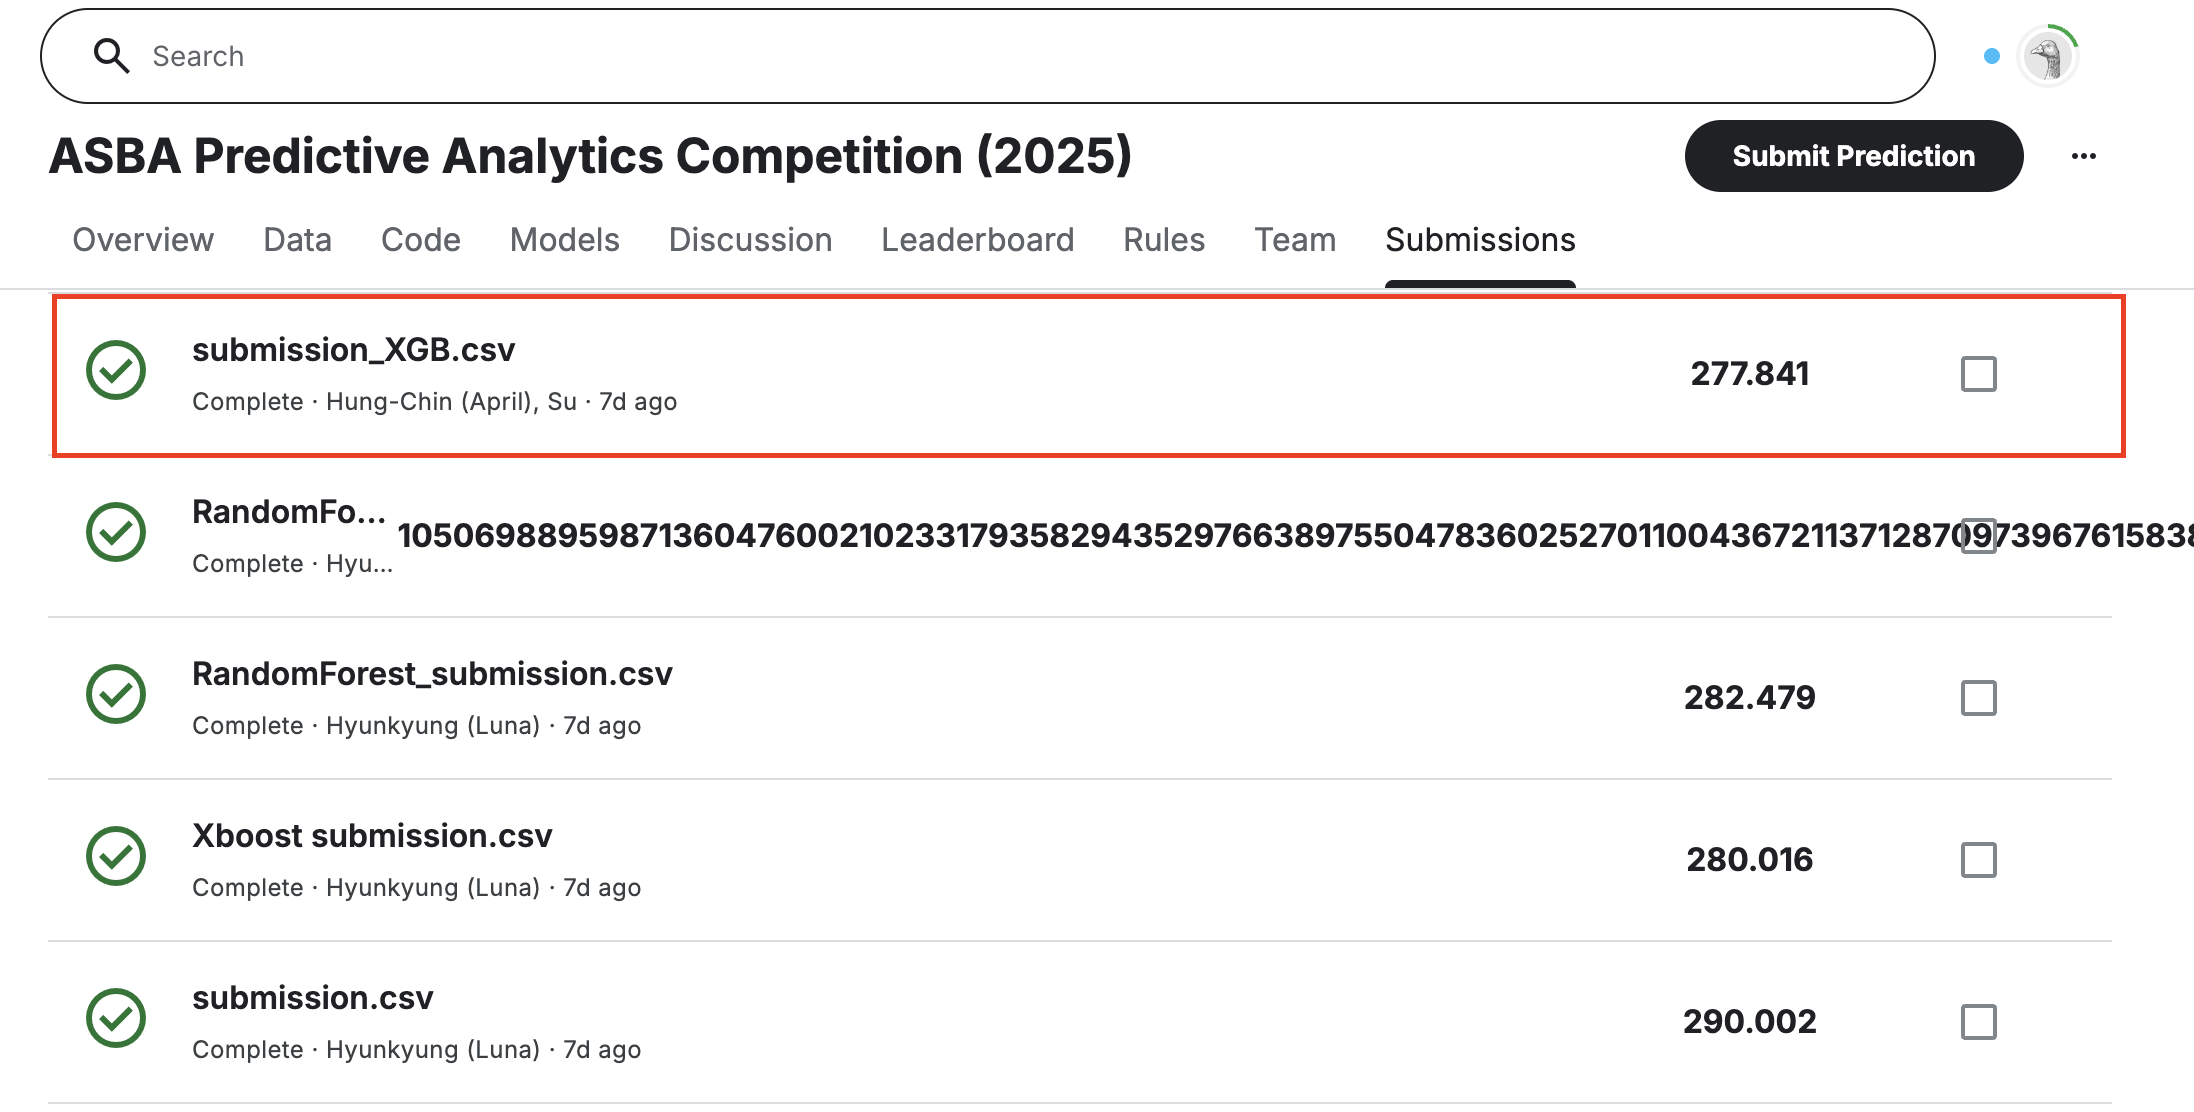

As shown in the screenshot, our previous submission (277.841) used the IQR (Interquartile Range) method to remove outliers from the price data. We chose IQR because house prices often contain extreme values, but soon realized that this approach was too aggressive, removing not only true outliers, but also many valid listings due to the right-skewed distribution. This reduced the amount of useful data for our model and impacted performance. To improve this, we reviewed the most extreme outliers by sorting prices and checking them with columns like bedrooms and neighbourhood, removing only the unreasonable values. Then, we applied a log transformation to the price variable to make the distribution more symmetric and reduce the impact of outliers. This change helped us to keep more meaningful data and have a better score on Kaggle.

---
---
## Marking Criteria

To receive full marks your solutions must satisfy the following criteria:

- Problem Description: 9 marks
- Data Cleaning: 9 marks
- Building Forecasting models: 9 marks
- Video Presentation: 3 marks
    - Duration less than 15 min, presentation skill and content
    - Each team member delivers a 5-minute presentation on their assigned task
    - All assignment questions must be discussed on video  
    - Your code must be readable on the video
    - Discuss both the actions you took and, more importantly, the reasoning behind these actions, explaining the significance of key steps
    - During the video recording, make sure that both your face and Jupyter Notebook are clearly visible
- Forecasts correctly uploaded to Kaggle
- Python code is clean and concise
- Written explanations are provided in clear and easy to understand sentences
- The assignment notebook is well-organised and easy to follow
- Failure to meet the above marking criteria will result in a deduction of marks

---
---